In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")

In [2]:
DATA_PATH = Path("../data/PhiUSIIL_Phishing_URL_Dataset.csv")

df = pd.read_csv(DATA_PATH)

df.head()

,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1
3,554095.txt,https://www.sfnmjournal.com,26,www.sfnmjournal.com,19,0,com,100.0,1.000000,0.522907,...,1,1,1,3,27,15,22,1,31,1
4,151578.txt,https://www.rewildingargentina.org,33,www.rewildingargentina.org,26,0,org,100.0,1.000000,0.079963,...,1,0,1,244,15,34,72,1,85,1


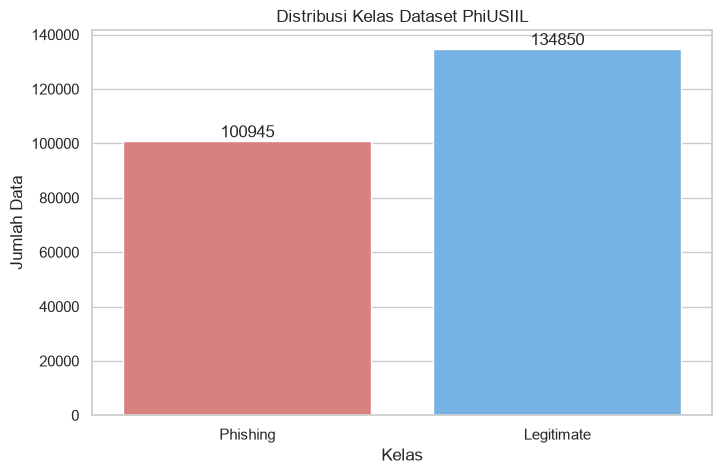

In [3]:
plt.figure(figsize=(8, 5))

ax = sns.countplot(
    data=df,
    x='label',
    hue='label',
    palette=['#E57373', '#64B5F6'],
    legend=False
)

plt.title('Distribusi Kelas Dataset PhiUSIIL')
plt.xlabel('Kelas')
plt.ylabel('Jumlah Data')
plt.xticks([0, 1], ['Phishing', 'Legitimate'])

for container in ax.containers:
    ax.bar_label(container)

plt.show()

In [4]:
numeric_df = df.select_dtypes(include=np.number)

correlation = numeric_df.corr()['label'].drop('label')

top_correlation = correlation.abs().sort_values(
    ascending=False
).head(15)

top_correlation

URLSimilarityIndex       0.860358
HasSocialNet             0.784255
HasCopyrightInfo         0.743358
HasDescription           0.690232
IsHTTPS                  0.609132
DomainTitleMatchScore    0.584905
HasSubmitButton          0.578561
IsResponsive             0.548608
URLTitleMatchScore       0.539419
SpacialCharRatioInURL    0.533537
HasHiddenFields          0.507731
HasFavicon               0.493711
URLCharProb              0.469749
CharContinuationRate     0.467735
HasTitle                 0.459725
Name: label, dtype: float64

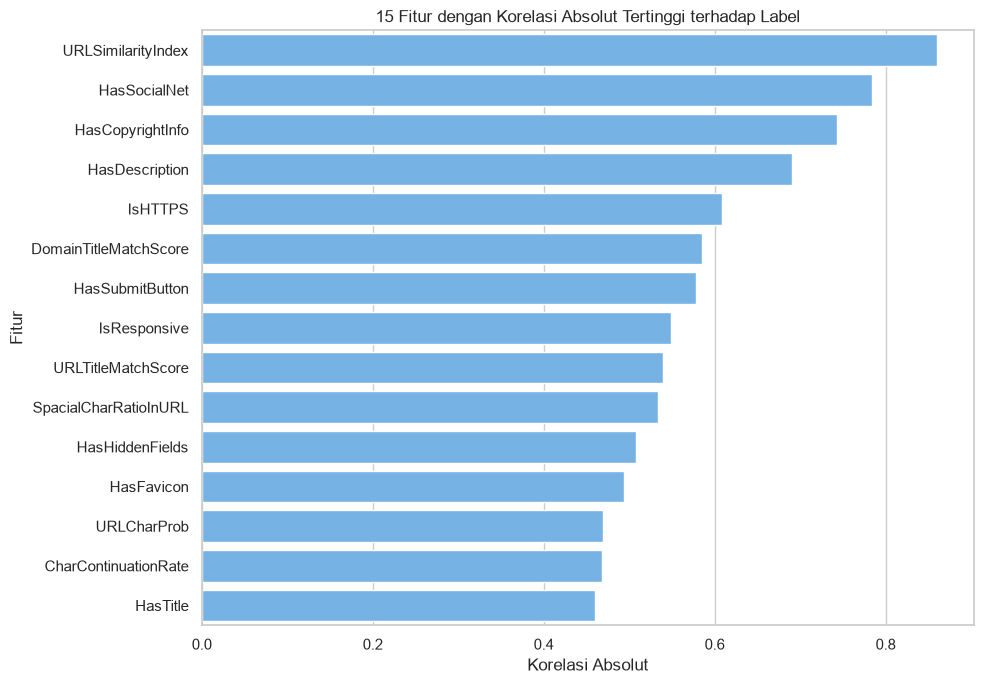

In [5]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=top_correlation.values,
    y=top_correlation.index,
    color='#64B5F6'
)

plt.title('15 Fitur dengan Korelasi Absolut Tertinggi terhadap Label')
plt.xlabel('Korelasi Absolut')
plt.ylabel('Fitur')

plt.tight_layout()
plt.show()

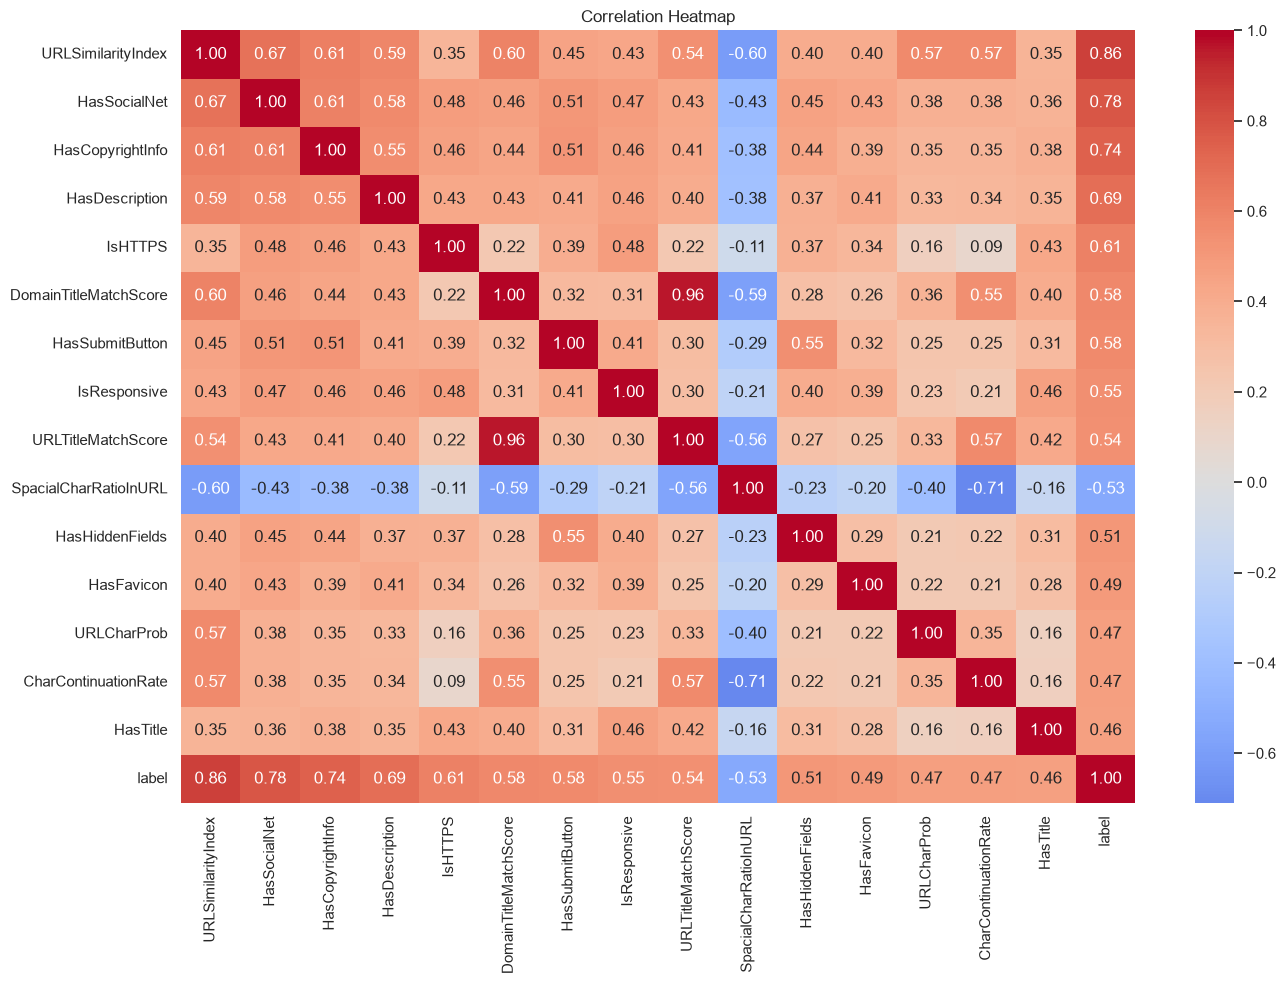

In [6]:
selected_features = top_correlation.index.tolist()

selected_features.append('label')

plt.figure(figsize=(14, 10))

sns.heatmap(
    df[selected_features].corr(),
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0
)

plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

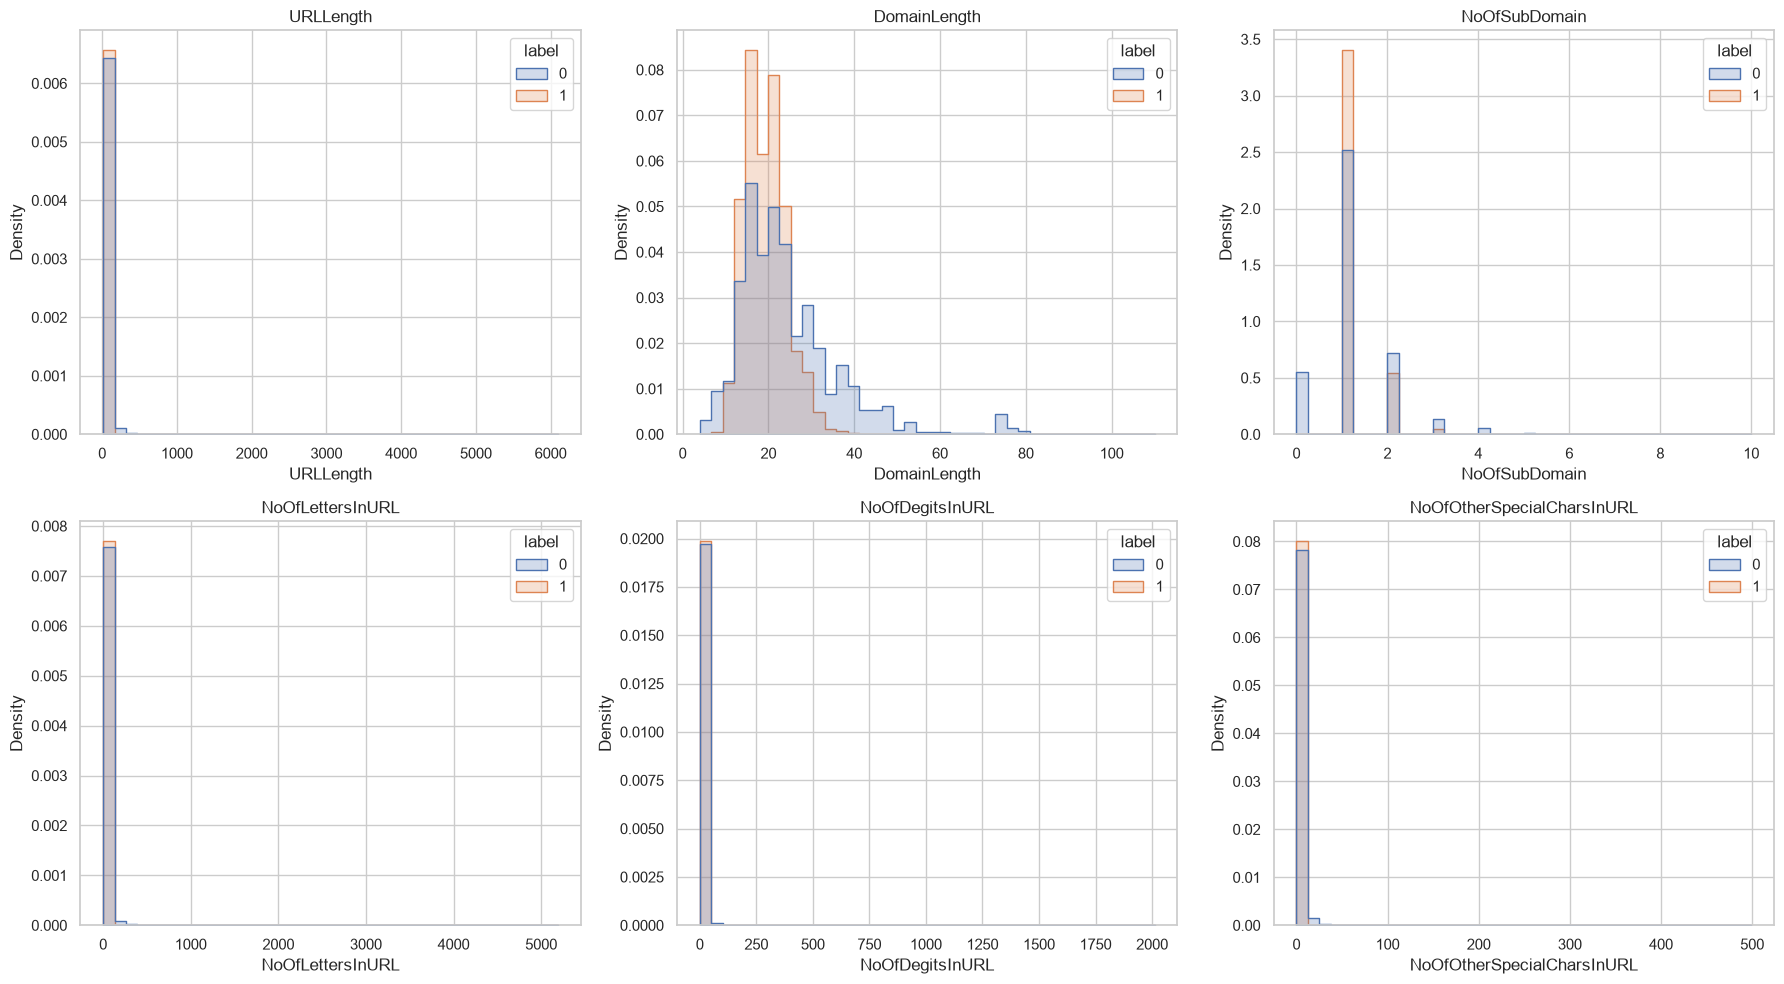

In [7]:
url_features = [
    'URLLength',
    'DomainLength',
    'NoOfSubDomain',
    'NoOfLettersInURL',
    'NoOfDegitsInURL',
    'NoOfOtherSpecialCharsInURL'
]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))

for feature, ax in zip(url_features, axes.flatten()):

    sns.histplot(
        data=df,
        x=feature,
        hue='label',
        bins=40,
        element='step',
        stat='density',
        common_norm=False,
        ax=ax
    )

    ax.set_title(feature)

plt.tight_layout()
plt.show()

In [8]:
suspected_features = [
    'URLSimilarityIndex',
    'TLDLegitimateProb',
    'URLCharProb'
]

df.groupby('label')[suspected_features].agg(
    ['min', 'max', 'mean', 'std']
)

URLSimilarityIndex                               TLDLegitimateProb  \
                     min    max        mean        std               min   
label                                                                      
0               0.155574  100.0   49.616973  22.572082      0.000000e+00   
1             100.000000  100.0  100.000000   0.000000      6.000000e-07   

                                    URLCharProb                                
            max      mean       std         min       max      mean       std  
label                                                                          
0      0.522907  0.232099  0.254775    0.001083  0.090681  0.049999  0.011634  
1      0.522907  0.281625  0.247132    0.002259  0.090824  0.060050  0.007171

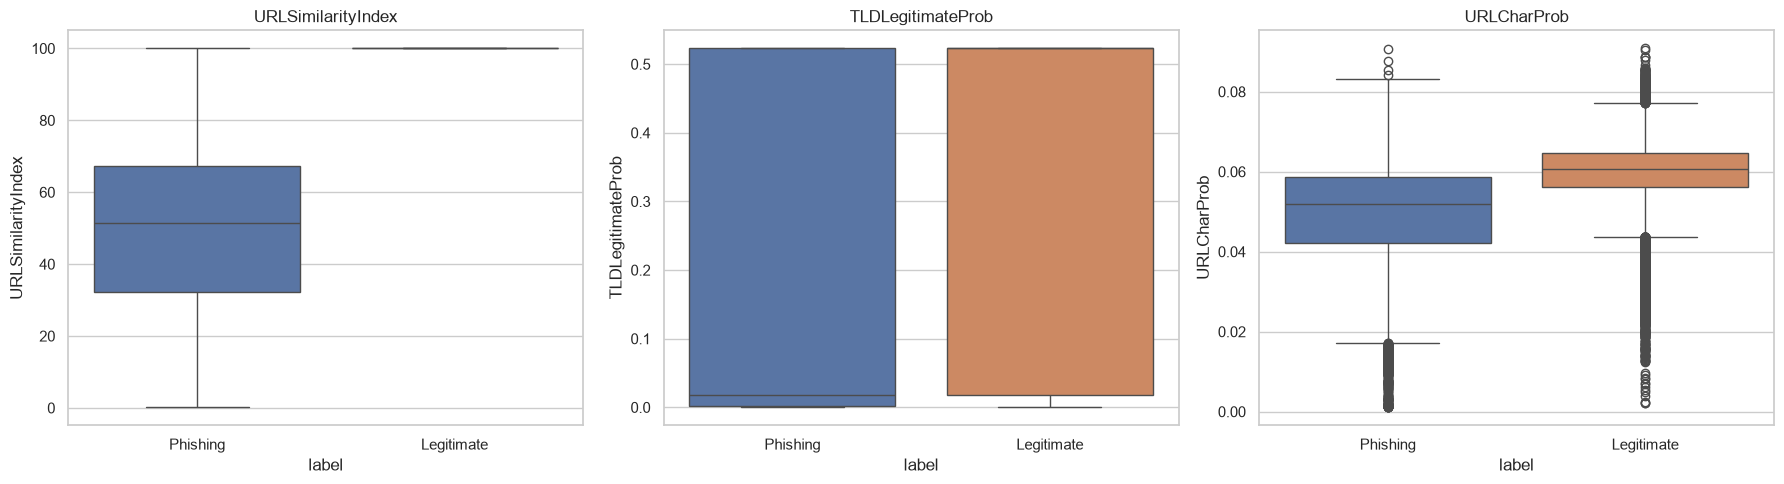

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for feature, ax in zip(suspected_features, axes):

    sns.boxplot(
        data=df,
        x='label',
        y=feature,
        hue='label',
        legend=False,
        ax=ax
    )

    ax.set_title(feature)
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Phishing', 'Legitimate'])

plt.tight_layout()
plt.show()

In [10]:
domain_counts = df['Domain'].value_counts()

print("Jumlah domain unik:", len(domain_counts))

print("Domain muncul satu kali:",
      (domain_counts == 1).sum())

print("Domain muncul lebih dari satu kali:",
      (domain_counts > 1).sum())

print("Frekuensi domain tertinggi:",
      domain_counts.max())

Jumlah domain unik: 220086
Domain muncul satu kali: 214560
Domain muncul lebih dari satu kali: 5526
Frekuensi domain tertinggi: 1197


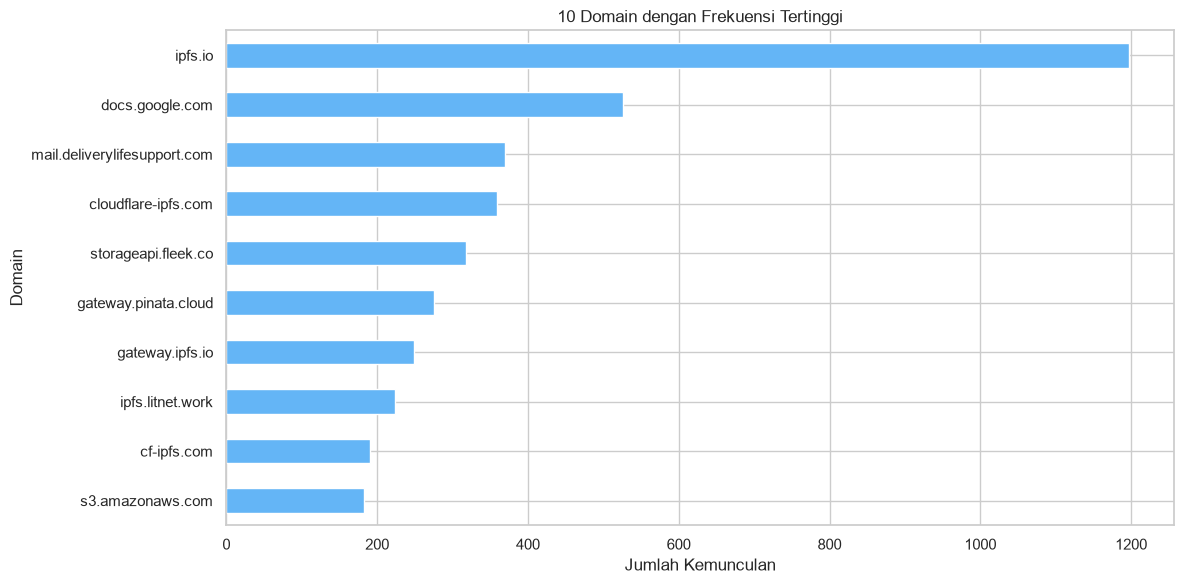

In [11]:
plt.figure(figsize=(12, 6))

domain_counts.head(10).sort_values().plot(
    kind='barh',
    color='#64B5F6'
)

plt.title('10 Domain dengan Frekuensi Tertinggi')
plt.xlabel('Jumlah Kemunculan')
plt.ylabel('Domain')

plt.tight_layout()
plt.show()

In [12]:
domain_label = df.groupby('Domain')['label'].nunique()

mixed_domains = domain_label[domain_label > 1]

print("Jumlah domain dengan label berbeda:",
      len(mixed_domains))

Jumlah domain dengan label berbeda: 54


In [13]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(
    df,
    test_size=0.3,
    random_state=42,
    stratify=df['label']
)

train_domains = set(train_df['Domain'])
test_domains = set(test_df['Domain'])

overlapping_domains = train_domains.intersection(test_domains)

print("Jumlah domain training:", len(train_domains))
print("Jumlah domain testing:", len(test_domains))
print("Jumlah domain overlap:", len(overlapping_domains))

print(
    "Persentase domain testing yang overlap:",
    round(len(overlapping_domains) / len(test_domains) * 100, 2),
    "%"
)

Jumlah domain training: 155197
Jumlah domain testing: 67616
Jumlah domain overlap: 2727
Persentase domain testing yang overlap: 4.03 %


Berdasarkan hasil Exploratory Data Analysis (EDA) terhadap dataset PhiUSIIL, pembagian data secara acak dengan rasio 70:30 menghasilkan 2.727 domain yang muncul pada data pelatihan dan pengujian, atau sebesar 4,03% dari total domain pengujian. Kondisi tersebut berpotensi menyebabkan evaluasi performa model menjadi terlalu optimistis karena sebagian domain pengujian telah ditemukan pada data pelatihan. Oleh karena itu, penelitian ini akan membandingkan random split dengan domain-grouped split untuk mengevaluasi kemampuan generalisasi model terhadap domain yang belum pernah ditemukan selama pelatihan.